In [3]:
# Run this cell once to make the workshop helper modules available.
import io
import os
import sys
import zipfile
from pathlib import Path
from urllib.request import urlopen

# Download all repository files once per Colab runtime, including helper modules.
if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/Data-Analysis-Workshop-main")
    if not REPO_DIR.is_dir():
        archive_url = "https://github.com/bajon1/Data-Analysis-Workshop/archive/refs/heads/main.zip"
        with urlopen(archive_url, timeout=60) as response:
            with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
                archive.extractall(REPO_DIR.parent)
else:
    REPO_DIR = Path.cwd()
    if REPO_DIR.name == "notebooks":
        REPO_DIR = REPO_DIR.parent

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f"Workshop repository: {REPO_DIR}")


Workshop repository: C:\Users\piotr\Projects\Data-Analysis-Workshop


# Data Analysis Workshop

## What you will learn

Use a real survey to practise reading a table, selecting answers, handling missing responses, and drawing clear plots. No programming experience is assumed.

The course uses OSMI's [Mental Health in Tech Survey](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey), described by its publisher as the 2014 survey. We describe workplace arrangements and reported support. We do not diagnose respondents or estimate the prevalence of mental illness.

The exercises use a small workplace-related subset. Gender, age, location, family history, treatment history, and free-text comments are outside the exercise dataset. The complete field dictionary below explains the original file without using those columns in analyses.

Run the helper cell above once, then follow Parts 0–3 in order. Later parts introduce leakage, LLM workflows, and synthetic text examples. There is no timetable.


## Part 0: Setup — download a table

A **DataFrame** is a table: one row per survey response and one column per question. The cell below downloads `survey.csv` from Kaggle and reads it into a DataFrame named `df_raw`.

`kagglehub` locates the downloaded file; `pd.read_csv(...)` opens it. No dataset is bundled with this repository. The file is small enough to read in full.

Only the next cell selects the columns we will use. We do not display rows from the full survey.


In [4]:
%pip -q install kagglehub

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

data_file = kagglehub.dataset_download(
    "osmi/mental-health-in-tech-survey",
    path="survey.csv",
)
df_raw = pd.read_csv(data_file)
print("Survey responses:", len(df_raw))



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Survey responses: 1259


### Our working table

We keep the same six columns throughout the practical exercises.

| Column | Meaning in this course | What we practise |
|---|---|---|
| `remote_work` | Works remotely at least half the time | Select a group and compare proportions |
| `self_employed` | Reports being self-employed | Find and label missing answers |
| `benefits` | Reports employer mental-health benefits | Count and plot answers |
| `care_options` | Knows the employer's care options | Distinguish knowledge from availability |
| `wellness_program` | Reports employer discussion of mental health in a wellness program | Adapt a plot |
| `seek_help` | Reports employer resources about mental health and seeking help | Practise the same pattern on another question |

These are participants' reports, not an audit of employer policy. A “Don't know” answer has its own meaning and should stay visible.

The selection below makes a separate table called `df`. The brackets will be explained in Part 1.


In [5]:
workshop_columns = [
    "remote_work",
    "self_employed",
    "benefits",
    "care_options",
    "wellness_program",
    "seek_help",
]

df = df_raw[workshop_columns].copy()
df.head()


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No
3,No,NaN,No,Yes,No,No
4,Yes,NaN,Yes,No,Don't know,Don't know


### Field dictionary for the original file

The question descriptions below follow the assignment and the [publisher's data card](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey). They document the source; they are not a list of features to feed into a predictive model.

| Column | Description |
|---|---|
| `Timestamp` | When the survey response was submitted. |
| `Age` | Age. |
| `Gender` | Gender. |
| `Country` | Country. |
| `state` | US state or territory, if the respondent lives in the United States. |
| `self_employed` | Are you self-employed? |
| `family_history` | Do you have a family history of mental illness? |
| `treatment` | Have you sought treatment for a mental health condition? |
| `work_interfere` | If you have a mental health condition, does it interfere with your work? |
| `no_employees` | How many employees does your company or organization have? |
| `remote_work` | Do you work remotely, outside an office, at least 50% of the time? |
| `tech_company` | Is your employer primarily a tech company or organization? |
| `benefits` | Does your employer provide mental health benefits? |
| `care_options` | Do you know the mental health care options your employer provides? |
| `wellness_program` | Has your employer discussed mental health as part of an employee wellness program? |
| `seek_help` | Does your employer provide resources about mental health issues and seeking help? |
| `anonymity` | Is anonymity protected when using mental health or substance abuse treatment resources? |
| `leave` | How easy is it to take medical leave for a mental health condition? |
| `mental_health_consequence` | Could discussing a mental health issue with your employer have negative consequences? |
| `phys_health_consequence` | Could discussing a physical health issue with your employer have negative consequences? |
| `coworkers` | Would you discuss a mental health issue with coworkers? |
| `supervisor` | Would you discuss a mental health issue with direct supervisors? |
| `mental_health_interview` | Would you raise a mental health issue in an interview with a potential employer? |
| `phys_health_interview` | Would you raise a physical health issue in an interview with a potential employer? |
| `mental_vs_physical` | Does your employer take mental health as seriously as physical health? |
| `obs_consequence` | Have you heard of or observed negative consequences for coworkers with mental health conditions? |
| `comments` | Additional free-text comments. Not used in this course. |

`treatment` records reported treatment-seeking, **not a diagnosis**. The source also contains personal and potentially identifying information; selecting a subset does not by itself prove anonymity. The dataset is a self-selected survey, so its percentages describe these responses, not all workers.


## Part 1: Reading Python — functions, methods, and brackets

### Calling a function or a method

Parentheses `()` mean **call this operation**. Values inside them are its inputs, called arguments.

| Example | How to read it |
|---|---|
| `len(df)` | Call the **function** `len` with the table as its input. |
| `print("Hello")` | Call the **function** `print` with some text. |
| `df.head(3)` | Call the **method** `head`, attached to `df`, asking for 3 rows. |
| `df.head()` | Call the same method using its default number of rows. |
| `df.shape` | Read a stored **attribute**: the numbers of rows and columns. No parentheses. |

A function is written as `function(input)`; a method as `object.method(input)`. A dot can also identify a library: `pd.read_csv(file)` is a function in pandas, not a method of a table.

`=` stores a value under a name. It is different from `==`, which asks whether two values are equal.


In [6]:
print("Number of rows:", len(df))
print("Rows and columns:", df.shape)
df.head(3)


Number of rows: 1259
Rows and columns: (1259, 6)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No


### Exercise 1: change an argument

Display the first **2** rows of the working table and print how many responses it contains.

**Hint:** Reuse the two operations above. Change the number inside `head(...)`; the argument to `len(...)` stays `df`.

<details>
<summary>Check after trying</summary>

```python
print("Number of rows:", len(df))
df.head(2)
```

</details>


In [7]:
print("Number of rows:", len(df))
# Change the number below.
df.head(3)


Number of rows: 1259


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No


### Square brackets select things

Square brackets `[]` mean **select**, not call.

Python counts positions from **0**. For the small list below, `answers[0]` selects its first item. The slice `answers[0:2]` includes positions 0 and 1; the stopping position 2 is excluded.

For a table, `df["benefits"]` selects one column as a Series. To keep several columns as a table, put a list of names inside the table's brackets: `df[["benefits", "care_options"]]`.

Quotes mark text: the spelling and capitalization of column names must match.


In [8]:
answers = ["Yes", "No", "Don't know"]
print("First answer:", answers[0])
print("First two answers:", answers[0:2])

df[["benefits", "care_options"]].head(3)


First answer: Yes
First two answers: ['Yes', 'No']


,benefits,care_options
0,Yes,Not sure
1,Don't know,No
2,No,No


### Exercise 2: select two questions

Show the first 5 rows of **remote_work** and **wellness_program**, in that order.

**Hint:** Keep the double brackets from the example. Replace only the two quoted column names and the argument to `head`.

<details>
<summary>Check after trying</summary>

```python
df[["remote_work", "wellness_program"]].head(5)
```

</details>


In [9]:
# Replace the column names and the row count.
df[["benefits", "care_options"]].head(3)


,benefits,care_options
0,Yes,Not sure
1,Don't know,No
2,No,No


### Select rows with a question

`df["remote_work"] == "Yes"` asks a question for every row. Its result is a list of `True` and `False` values.

Putting that result inside `df[...]` keeps the rows marked `True`. Read the following in two steps: **ask a question**, then **keep matching rows**. No special row-indexing method is needed.


In [10]:
works_remotely = df["remote_work"] == "Yes"
remote_workers = df[works_remotely]
remote_workers.head(3)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
4,Yes,NaN,Yes,No,Don't know,Don't know
6,Yes,NaN,No,No,No,No
7,Yes,NaN,No,Yes,No,No


### Exercise 3: change the selection

Show the first 3 responses from people who answered **No** to `remote_work`.

**Hint:** Reuse the two-step filter. The question is the same; change the answer being matched from `"Yes"` to `"No"`.

<details>
<summary>Check after trying</summary>

```python
office_rows = df["remote_work"] == "No"
df[office_rows].head(3)
```

</details>


In [11]:
# Adapt the answer and the variable names if you wish.
matching_rows = df["remote_work"] == "Yes"
df[matching_rows].head(3)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
4,Yes,NaN,Yes,No,Don't know,Don't know
6,Yes,NaN,No,No,No,No
7,Yes,NaN,No,Yes,No,No


## Part 2: Cleaning — see the problem before changing the table

### Count missing answers

`isna()` marks missing values with `True`; `sum()` counts those marks. Both are methods. Reading `df.isna().sum()` from left to right means: **find missing answers, then count them for each column**.

A blank answer is different from `"Don't know"`, `"Not sure"`, or `"No"`. Those are recorded answers, not missing values.

The selected `self_employed` question gives us an example of actual missing answers, without using demographic fields.


remote_work          0
self_employed       18
benefits             0
care_options         0
wellness_program     0
seek_help            0
dtype: int64


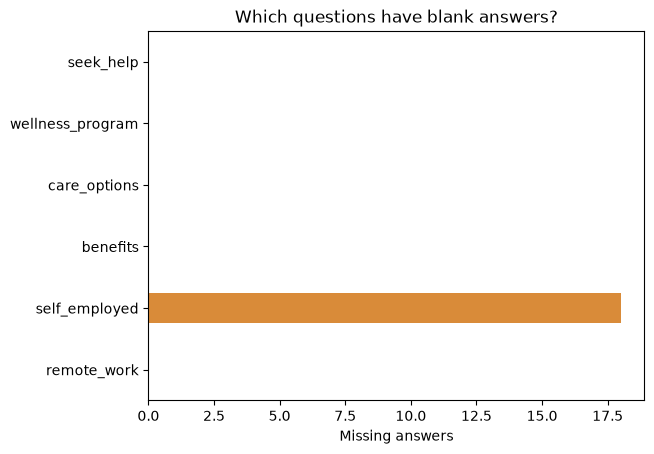

In [12]:
missing_answers = df.isna().sum()
print(missing_answers)

missing_answers.plot.barh(color="#d98b39")
plt.xlabel("Missing answers")
plt.title("Which questions have blank answers?")
plt.show()


### Exercise 4: inspect one question

Count missing answers in **self_employed** only.

**Hint:** First select the column using `df["..."]`. Then use exactly the same `.isna().sum()` chain as above.

<details>
<summary>Check after trying</summary>

```python
df["self_employed"].isna().sum()
```

</details>


In [13]:
# Change the selected question.
df["remote_work"].isna().sum()


np.int64(0)

### Make missingness visible without guessing an answer

Before changing real data, try the operation on three invented answers. `pd.Series(...)` creates a single column. `fillna("No answer")` labels its blank entry.

This label is a reporting choice, not an estimate of what the person would have answered. It leaves `"Yes"`, `"No"`, and uncertainty answers unchanged.

`copy()` makes a separate working table so the original is available for comparison.


In [14]:
example_answers = pd.Series(["Yes", None, "No"])
example_answers.fillna("No answer")


0          Yes
1    No answer
2           No
dtype: str

### Exercise 5: label missing responses

Make a separate table named **df_clean**, replacing only missing entries in `df` with **"No answer"**.

**Hint:** The example used `.fillna("No answer")` on one column. The same method also works on the entire table: call it on `df`, and store its result with `df_clean = ...`.

<details>
<summary>Check after trying</summary>

```python
df_clean = df.fillna("No answer")
df_clean.head(3)
```

</details>


In [15]:
# Replace the operation on the right using the example above.
df_clean = df.copy()
df_clean.head(3)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No


### Continue from a common working table

After checking Exercise 5, run the cell below so later examples all start from the same cleaned table.

`value_counts()` counts each recorded answer. `dropna=False` asks it to show blanks too, if any remain. Named arguments use `name=value` inside the parentheses.

Do **not** remove repeated rows just because people gave the same six answers. Different respondents can legitimately choose the same categories.


In [16]:
df_clean = df.fillna("No answer")
df_clean["self_employed"].value_counts(dropna=False)


self_employed
No           1095
Yes           146
No answer      18
Name: count, dtype: int64

### Exercise 6: keep uncertainty answers

Count the responses to **care_options**. Keep **"Not sure"** visible, and explain why it should not be changed to **"No"**.

**Hint:** Select another column and reuse `.value_counts(dropna=False)`. Count labels as recorded; not knowing the answer is different from saying a service is unavailable.

<details>
<summary>Check after trying</summary>

```python
df_clean["care_options"].value_counts(dropna=False)
```

</details>


In [17]:
# Change the column; keep the counting method.
df_clean["self_employed"].value_counts(dropna=False)


self_employed
No           1095
Yes           146
No answer      18
Name: count, dtype: int64

## Part 3: Describe and visualise — one question at a time

### Count answers and draw a bar chart

Start with a concrete question: **What do these respondents report about employer mental-health benefits?**

Save the answer counts, then plot them. `plot.barh()` draws horizontal bars; their lengths show the counts. The `plt` functions label the picture. Changing a title changes the label, not the data.

Keep `"Don't know"` in the chart. It describes uncertainty about support, not proof that support is absent.


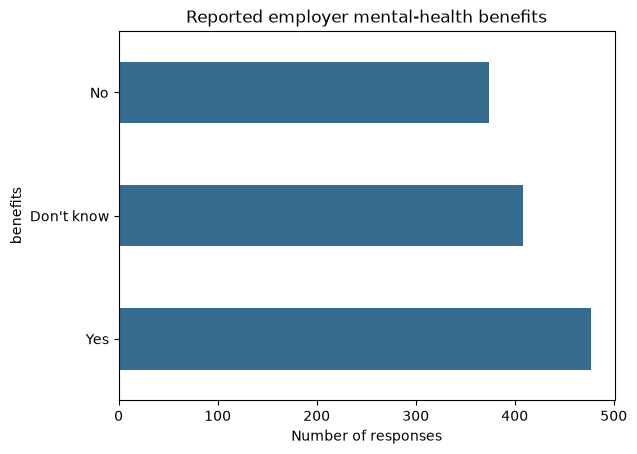

In [18]:
benefit_counts = df_clean["benefits"].value_counts()
benefit_counts.plot.barh(color="#356b8e")
plt.xlabel("Number of responses")
plt.title("Reported employer mental-health benefits")
plt.show()


### Exercise 7: adapt a chart

Draw the same kind of bar chart for **wellness_program**. Give the chart a title that names that question.

**Hint:** Copy the example's pattern. Change the column, use a new counts variable, and update the title. The plotting and labeling operations stay the same.

<details>
<summary>Check after trying</summary>

```python
wellness_counts = df_clean["wellness_program"].value_counts()
wellness_counts.plot.barh(color="#356b8e")
plt.xlabel("Number of responses")
plt.title("Reported employer wellness-program discussion")
plt.show()
```

</details>


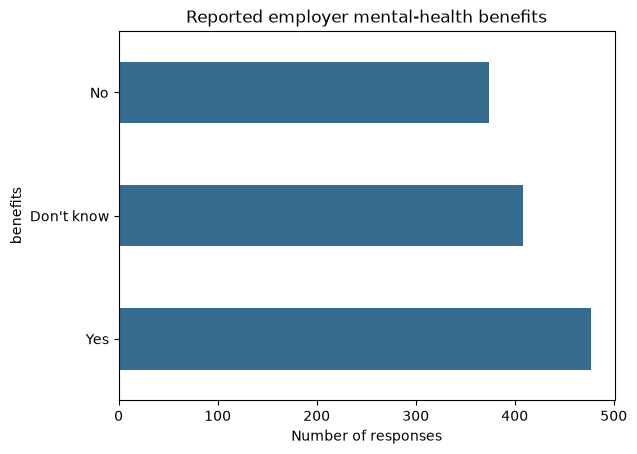

In [19]:
# Adapt the column, counts variable, and title.
counts = df_clean["benefits"].value_counts()
counts.plot.barh(color="#356b8e")
plt.xlabel("Number of responses")
plt.title("Reported employer mental-health benefits")
plt.show()


### Counts and percentages answer different questions

`value_counts(normalize=True)` returns shares instead of counts. Multiplying by 100 converts a share to a percentage; `round(1)` displays one decimal place.

The denominator here is **all rows in df_clean**, including “Don't know” and “No answer”. Do not quietly remove those categories and keep the same interpretation.

Describe the result as a percentage **of these survey responses**. This self-selected sample is not a representative estimate of all tech workers.


In [20]:
benefit_percent = df_clean["benefits"].value_counts(normalize=True) * 100
print("Denominator:", len(df_clean), "responses")
benefit_percent.round(1)


Denominator: 1259 responses


benefits
Yes           37.9
Don't know    32.4
No            29.7
Name: proportion, dtype: float64

### Exercise 8: reuse a percentage calculation

Show answer percentages for **seek_help**, rounded to one decimal place. State the denominator.

**Hint:** Use the same `.value_counts(normalize=True) * 100` pattern. Change the question and the variable name, then call `.round(1)`.

<details>
<summary>Check after trying</summary>

```python
help_percent = df_clean["seek_help"].value_counts(normalize=True) * 100
print("Denominator:", len(df_clean), "responses")
help_percent.round(1)
```

</details>


In [21]:
# Change the question to seek_help.
percentages = df_clean["benefits"].value_counts(normalize=True) * 100
print("Denominator:", len(df_clean), "responses")
percentages.round(1)


Denominator: 1259 responses


benefits
Yes           37.9
Don't know    32.4
No            29.7
Name: proportion, dtype: float64

### Compare groups without confusing group size with support

Question: **How do reported benefits differ between respondents working remotely and those not working remotely?**

`pd.crosstab(first_column, second_column)` is a pandas **function**. It counts combinations: the first question labels rows and the second labels columns. First look at the counts so the group sizes are visible.


In [22]:
benefits_by_remote_counts = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
)
benefits_by_remote_counts


benefits,Don't know,No,Yes
remote_work,,,
No,282,241,360
Yes,126,133,117


Adding `normalize="index"` changes each row to shares within that group. After multiplying by 100, every row totals 100%.

`stacked=True` joins answer categories into one bar for each group. Comparing proportions helps when one group has more responses. Check the count table as well: a small group can have unstable percentages.


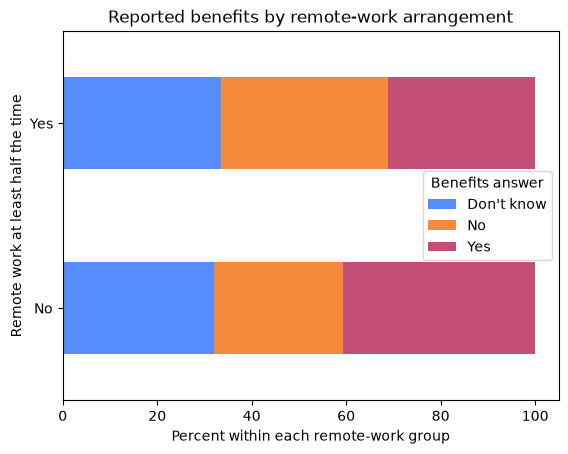

In [23]:
benefits_by_remote_percent = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
    normalize="index",
) * 100

benefits_by_remote_percent.plot.barh(stacked=True)
plt.xlabel("Percent within each remote-work group")
plt.ylabel("Remote work at least half the time")
plt.title("Reported benefits by remote-work arrangement")
plt.legend(title="Benefits answer")
plt.show()


### Exercise 9: combine familiar steps

Compare **wellness_program** answers between remote-work groups. Display a count table, then draw a within-group percentage chart.

**Hint:** Combine the two crosstab examples above. Keep `remote_work` as the first column, replace `benefits` with `wellness_program`, and keep `normalize="index"` only in the percentage table.

<details>
<summary>Check after trying</summary>

```python
wellness_by_remote_counts = pd.crosstab(
    df_clean["remote_work"], df_clean["wellness_program"]
)
display(wellness_by_remote_counts)

wellness_by_remote_percent = pd.crosstab(
    df_clean["remote_work"],
    df_clean["wellness_program"],
    normalize="index",
) * 100
wellness_by_remote_percent.plot.barh(stacked=True)
plt.xlabel("Percent within each remote-work group")
plt.ylabel("Remote work at least half the time")
plt.title("Reported wellness-program discussion by remote-work arrangement")
plt.legend(title="Wellness-program answer")
plt.show()
```

</details>


benefits,Don't know,No,Yes
remote_work,,,
No,282,241,360
Yes,126,133,117


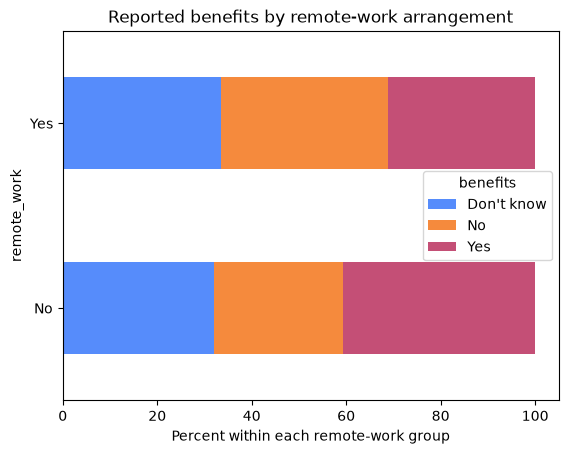

In [24]:
# Adapt both second-column names and the chart labels.
group_counts = pd.crosstab(df_clean["remote_work"], df_clean["benefits"])
display(group_counts)

group_percent = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
    normalize="index",
) * 100
group_percent.plot.barh(stacked=True)
plt.xlabel("Percent within each remote-work group")
plt.title("Reported benefits by remote-work arrangement")
plt.show()


### Exercise 10: interpret the picture, not a diagnosis

Write two sentences about one chart you produced:

1. Describe an observed answer pattern, naming the question and the denominator.
2. Give one reason the comparison does not establish a causal effect of remote work.

**Hint:** Reuse “among these survey responses”. Consider self-selection, unequal group sizes, unmeasured differences between employers, and uncertain answers. Do not infer anyone's diagnosis from the chart.

<details>
<summary>Check after trying</summary>

A suitable answer identifies the plotted categories and groups, reports the denominator, and avoids claiming that remote work caused a difference. The survey is observational and self-selected; association alone does not establish causation.

</details>


## Part 4: Data leakage — what would have been known beforehand?

**Data leakage** happens when a predictive task uses information that would not legitimately have been available at its intended prediction time. A model can then appear accurate for the wrong reason. See the [scikit-learn guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

Suppose someone tries to predict `treatment`: “Have you sought treatment for a mental health condition?” That is treatment-seeking, not a diagnosis or an objective measure of need.

Some survey answers describe a person's knowledge or perception of workplace support, including `mental_health_consequence`, `mental_health_interview`, `benefits`, and `care_options`. Someone who has already sought care may have learned more about available support or encountered negative workplace attitudes. Answers recorded **after** that experience can reflect the outcome we are trying to predict. A model may learn that consequence or proxy rather than useful prior information — potentially a near-tautological relationship.

This is a **risk to investigate**, not proof that every support feature leaks. For example, benefits may have existed before someone sought care. This cross-sectional file does not establish the required timeline. High accuracy alone would not resolve that problem.

| Proposed input | What must we ask? |
|---|---|
| `mental_health_consequence` | Was the perception recorded before or after the treatment-seeking experience? |
| `mental_health_interview` | Is this a prior attitude or an attitude shaped by experience of care and disclosure? |
| `benefits` or `care_options` | Did the support or knowledge of it exist and become measurable before the intended prediction? |
| A documented employer policy measured before care | Is it truly prior information, and does it fit the stated task? |

For a defensible predictive study, define a prediction date, target, population, and permitted information first. Use prospective or documented pre-outcome measurements; do not assume this survey supplies them. Split evaluation data before fitting preprocessing and keep the same person or employer from leaking across sets where applicable.

Our charts are **descriptive**, so we can discuss reported support without building a treatment classifier.


### Exercise 11: audit a tempting predictor

A colleague claims that using `mental_health_consequence`, `mental_health_interview`, and `benefits` to predict `treatment` must be useful because the classifier is accurate.

List two questions you would ask before accepting that result. Then explain why `benefits` is not automatically proven to be a leaking feature.

**Hint:** Use the table above. Ask when each answer was available, and whether it was affected by seeking treatment. Distinguish a possible causal story from a documented timeline.

<details>
<summary>Check after trying</summary>

Ask whether each input was measured before the prediction date and whether prior treatment affected the answer. Benefits could genuinely precede care, but the survey alone does not prove when employer support or the respondent's knowledge of it was measured. Accuracy cannot establish valid timing or clinical usefulness.

</details>


## Part 5: Ask an LLM for code without sharing responses

Use an LLM as a coding assistant. Give it the task, column names, and types; execute its proposed code in your own session. You do not need to paste survey rows.

`df_clean.dtypes` describes column types. The code below turns only that description into text. The braces in the `f"..."` string insert this schema and the task into a prompt.

For real research data, follow consent, institutional policy, and approved tools. Selecting columns, removing names, or masking a few patterns does not guarantee anonymity.


In [25]:
schema = df_clean.dtypes.astype(str).to_string()
task = "Write pandas code to count benefits answers, keeping Don't know visible."

prompt = f"""Suggest Python code; do not invent results.
Task: {task}
Column names and types:
{schema}
No respondent rows are included.
Explain the denominator and keep uncertainty answers visible.
"""
print(prompt)


Suggest Python code; do not invent results.
Task: Write pandas code to count benefits answers, keeping Don't know visible.
Column names and types:
remote_work         str
self_employed       str
benefits            str
care_options        str
wellness_program    str
seek_help           str
No respondent rows are included.
Explain the denominator and keep uncertainty answers visible.



### Exercise 12: make the request specific

Adapt the task sentence to ask for **seek_help percentages**, including uncertainty answers, with a labeled horizontal bar chart.

**Hint:** Change only the text in `task`; the starter repeats the prompt-building code above. Column names and types are enough. Do not append `df.head()` or survey comments.

<details>
<summary>Check after trying</summary>

```python
task = (
    "Write pandas code for seek_help answer percentages and a labeled horizontal "
    "bar chart. Keep Don't know and No answer visible and state the denominator."
)

prompt = f"""Suggest Python code; do not invent results.
Task: {task}
Column names and types:
{schema}
No respondent rows are included.
Explain the denominator and keep uncertainty answers visible.
"""
print(prompt)
```

</details>


In [26]:
# Edit the task sentence, then run this cell to build the revised prompt.
task = "Write pandas code to count benefits answers, keeping Don't know visible."

prompt = f"""Suggest Python code; do not invent results.
Task: {task}
Column names and types:
{schema}
No respondent rows are included.
Explain the denominator and keep uncertainty answers visible.
"""
print(prompt)


Suggest Python code; do not invent results.
Task: Write pandas code to count benefits answers, keeping Don't know visible.
Column names and types:
remote_work         str
self_employed       str
benefits            str
care_options        str
wellness_program    str
seek_help           str
No respondent rows are included.
Explain the denominator and keep uncertainty answers visible.



### Check the suggested code

Compare the proposed operations with the examples you already ran. Check whether the LLM changed the denominator, discarded uncertain responses, invented columns, or made causal claims.

Use the [pandas documentation](https://pandas.pydata.org/docs/) and your IDE's help or completion tools to inspect an unfamiliar method. Share an error message and a small **invented** example when debugging, rather than repeatedly uploading the actual table.

A schema still deserves review: column names themselves can reveal confidential study topics. The synthetic text examples below are unrelated to respondents.


## Part 6: Masking and automated detection — synthetic text only

The survey's `comments` column is excluded. We demonstrate masking on an invented sentence instead.

`re.sub(pattern, replacement, text)` is a function that replaces text matching a pattern. The email pattern below is an example, not a complete detector of identifying information.


In [27]:
import re

synthetic_text = "Contact Alex Example at alex@example.org or +48 123 456 789."
email_pattern = r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}"

masked_text = re.sub(email_pattern, "[EMAIL]", synthetic_text)
print(masked_text)


Contact Alex Example at [EMAIL] or +48 123 456 789.


For the exact invented phone format `+48 123 456 789`, use the pattern `r"\+48 \d{3} \d{3} \d{3}"`. Here `\d{3}` means three digits. It does not cover every country's phone format.

The same `re.sub(...)` function can run a second replacement on text that has already had its email masked.


### Exercise 13: combine two replacements

Starting from **masked_text**, replace the invented phone number with **[PHONE]**. Keep the email masked.

**Hint:** Reuse `re.sub(pattern, replacement, text)`. Use the phone pattern just shown, `"[PHONE]"` as the replacement, and `masked_text` as the input.

<details>
<summary>Check after trying</summary>

```python
phone_pattern = r"\+48 \d{3} \d{3} \d{3}"
phone_masked = re.sub(phone_pattern, "[PHONE]", masked_text)
print(phone_masked)
```

</details>


In [28]:
# Replace the pattern and replacement; keep masked_text as input.
phone_masked = re.sub(email_pattern, "[EMAIL]", masked_text)
print(phone_masked)


Contact Alex Example at [EMAIL] or +48 123 456 789.


### Optional: Microsoft Presidio

Presidio can propose additional entities, but its output depends on installed language models and recognizers. Run the next two optional cells only if you want the demonstration. They use the same invented sentence, not survey responses.

The small spaCy English model is downloaded from its official release. Automated detection can miss names, indirect identifiers, or contextual details; it does not guarantee anonymisation.


In [ ]:
# OPTIONAL: install dependencies for the synthetic-text demonstration.
%pip -q install presidio-analyzer presidio-anonymizer
%pip -q install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl


In [ ]:
# OPTIONAL: run after the Presidio installation cell.
from presidio_analyzer import AnalyzerEngine
from presidio_analyzer.nlp_engine import NlpEngineProvider
from presidio_anonymizer import AnonymizerEngine

nlp_engine = NlpEngineProvider(
    nlp_configuration={
        "nlp_engine_name": "spacy",
        "models": [{"lang_code": "en", "model_name": "en_core_web_sm"}],
    }
).create_engine()
analyzer = AnalyzerEngine(nlp_engine=nlp_engine, supported_languages=["en"])
findings = analyzer.analyze(
    text=synthetic_text,
    language="en",
    entities=["PERSON", "EMAIL_ADDRESS", "PHONE_NUMBER"],
)
print(AnonymizerEngine().anonymize(text=synthetic_text, analyzer_results=findings).text)


## Part 7: Words and meaning — another synthetic example

**Bag of Words** counts words without understanding their meaning or order. A table of counts makes its behaviour visible.

The invented sentences below concern workplace support; they are not the survey's free-text comments. `fit_transform` learns a vocabulary and produces counts. `get_feature_names_out()` retrieves the learned words.


In [29]:
from sklearn.feature_extraction.text import CountVectorizer

sentences = [
    "the company offers mental health support",
    "the company offers mental health help",
    "I work from home",
    "I work remotely",
]

vectorizer = CountVectorizer(ngram_range=(1, 1))
word_counts = vectorizer.fit_transform(sentences)
word_table = pd.DataFrame(
    word_counts.toarray(),
    columns=vectorizer.get_feature_names_out(),
    index=sentences,
)
word_table


,company,from,health,help,home,mental,offers,remotely,support,the,work
the company offers mental health support,1,0,1,0,0,1,1,0,1,1,0
the company offers mental health help,1,0,1,1,0,1,1,0,0,1,0
I work from home,0,1,0,0,1,0,0,0,0,0,1
I work remotely,0,0,0,0,0,0,0,1,0,0,1


An **n-gram** is a sequence of neighbouring words. `ngram_range=(1, 1)` counts single words only; `ngram_range=(1, 2)` counts single words and two-word phrases.

The phrase “mental health” may be useful as a unit. Word counts still do not tell us that “work from home” and “work remotely” have similar meanings.


### Exercise 14: change one parameter

Rebuild the count table so it includes both single words and two-word phrases. Find **mental health** in its columns.

**Hint:** Use the same sentences, the same `fit_transform` call, and the same DataFrame construction. Change only `ngram_range` from `(1, 1)` to the option demonstrated above.

<details>
<summary>Check after trying</summary>

```python
phrase_vectorizer = CountVectorizer(ngram_range=(1, 2))
phrase_counts = phrase_vectorizer.fit_transform(sentences)
pd.DataFrame(
    phrase_counts.toarray(),
    columns=phrase_vectorizer.get_feature_names_out(),
    index=sentences,
)
```

</details>


In [30]:
# Change ngram_range; the remaining steps are the same as the example.
phrase_vectorizer = CountVectorizer(ngram_range=(1, 1))
phrase_counts = phrase_vectorizer.fit_transform(sentences)
pd.DataFrame(
    phrase_counts.toarray(),
    columns=phrase_vectorizer.get_feature_names_out(),
    index=sentences,
)


,company,from,health,help,home,mental,offers,remotely,support,the,work
the company offers mental health support,1,0,1,0,0,1,1,0,1,1,0
the company offers mental health help,1,0,1,1,0,1,1,0,0,1,0
I work from home,0,1,0,0,1,0,0,0,0,0,1
I work remotely,0,0,0,0,0,0,0,1,0,0,1


### Optional: sentence embeddings

Sentence embeddings represent sentences as numerical vectors. A similarity score can place paraphrases near one another even when they share few words. Such scores are not diagnoses, truth scores, or proof of a psychological relationship.

The next two optional cells install a library and download a small pretrained model. They use only the four invented sentences above. If the download is unavailable, discuss the contrast with word counts using the displayed examples.


In [ ]:
# OPTIONAL: install the library for the sentence-embedding demonstration.
%pip -q install sentence-transformers


In [ ]:
# OPTIONAL: downloads a pretrained model; uses synthetic sentences only.
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("sentence-transformers/paraphrase-MiniLM-L3-v2")
embeddings = embedding_model.encode(sentences)
similarities = embedding_model.similarity(embeddings, embeddings)
pd.DataFrame(similarities.numpy(), index=sentences, columns=sentences).round(2)


## Closing exercise: explain your workflow

In your own words, explain:

- how a function call differs from a method call and from selecting a column;
- why “No”, “Don't know”, and a missing answer should not be merged automatically;
- what denominator your chosen plot uses;
- why a treatment predictor may use information shaped by the outcome;
- what you can share with a coding assistant without sending respondent rows.

**Hint:** Revisit one worked example from Parts 1, 2, 3, 4, and 5. Prefer a clear descriptive question and a readable plot over an unsupported clinical or causal claim.

You now have a reproducible path from a source CSV to a documented, limited descriptive comparison. Adapt the question and the selected columns deliberately when using another survey.
